## Oresund

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements, error_mshred

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/mesh_EMOD.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

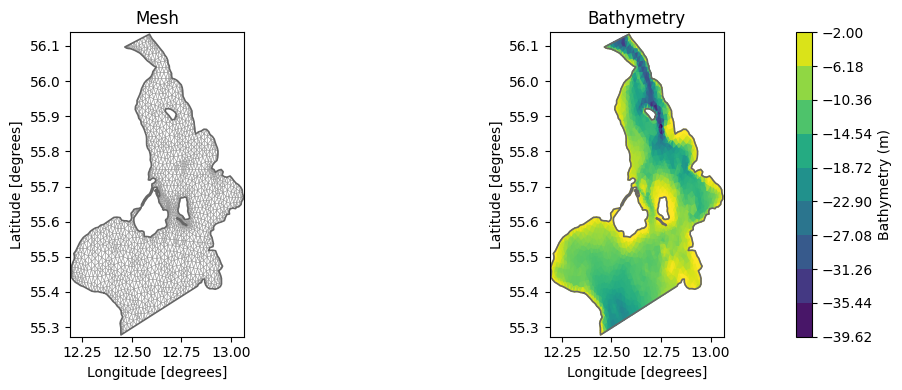

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

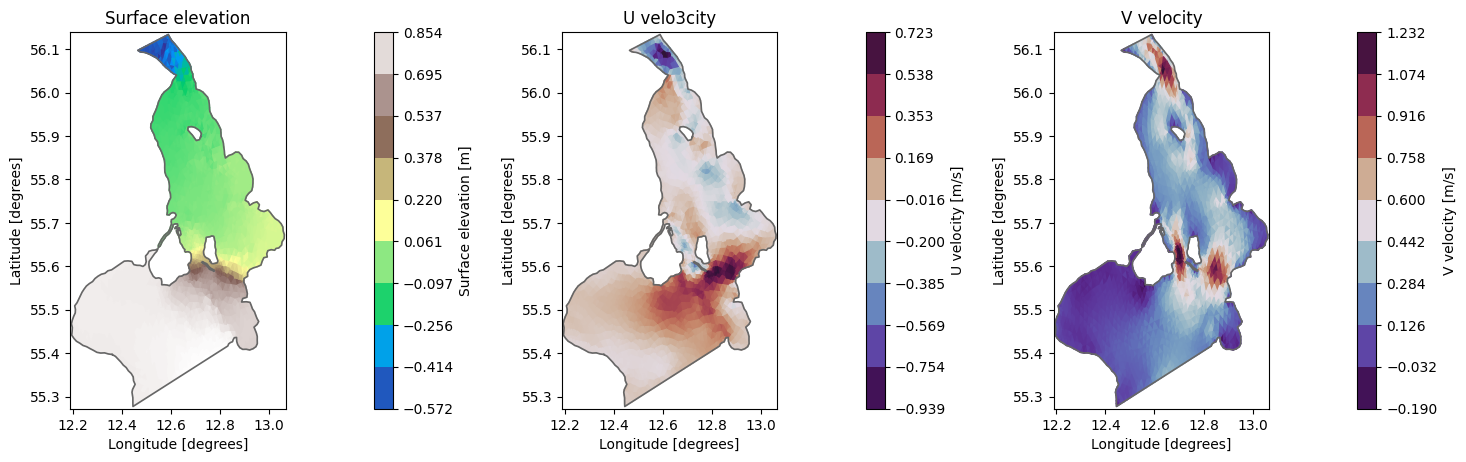

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


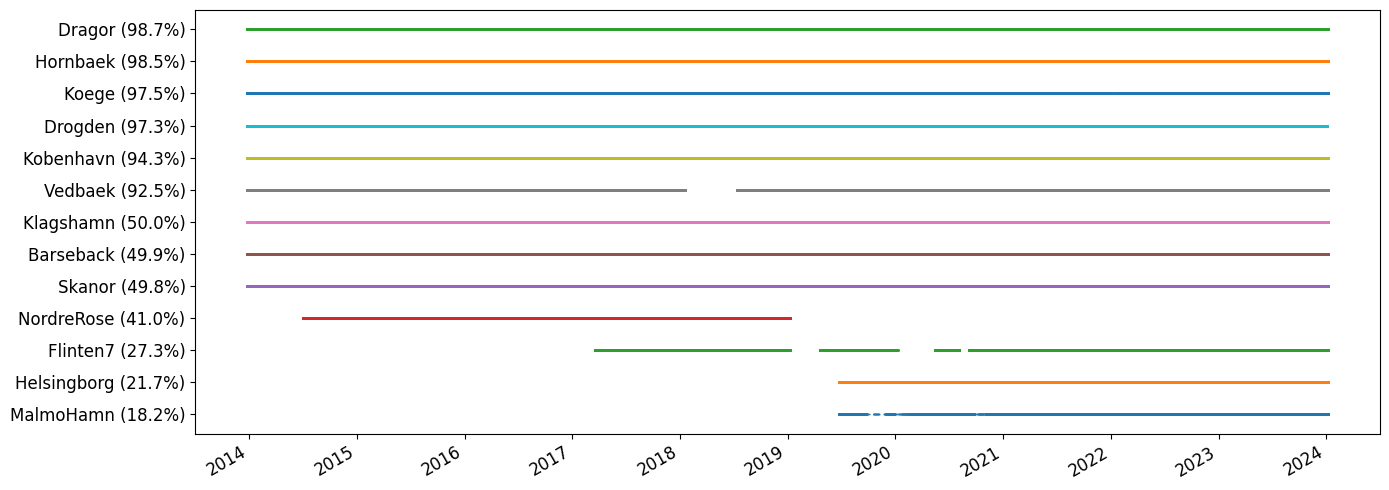

In [6]:
# sensor coverage
wllist = get_wl_point_obs()

# Compute station coverage against the simulation timeline
model_time = pd.DatetimeIndex(ds.time)
coverage_pct_by_name = {}
for obs in wllist:
    obs_time = pd.DatetimeIndex(obs.time)
    coverage_pct_by_name[obs.name] = 100.0 * model_time.isin(obs_time).sum() / len(model_time)

# Sort stations by coverage (highest first) before plotting
wllist_sorted = sorted(wllist, key=lambda obs: coverage_pct_by_name.get(obs.name, 0.0))
ax = ms.plotting.temporal_coverage(wllist_sorted)

# Make the plot wider and shorter
ax.figure.set_size_inches(14, 5)

# Append coverage % to each station label
yticks = ax.get_yticks()
current_labels = [tick.get_text() for tick in ax.get_yticklabels()]
updated_labels = []
for name in current_labels:
    pct = coverage_pct_by_name.get(name)
    updated_labels.append(f"{name} ({pct:.1f}%)" if pct is not None else name)

ax.set_yticks(yticks)
ax.set_yticklabels(updated_labels, fontsize=12)
ax.tick_params(axis="x", labelsize=12)
ax.set_xlabel(ax.get_xlabel(), fontsize=13)
plt.tight_layout()
plt.show()

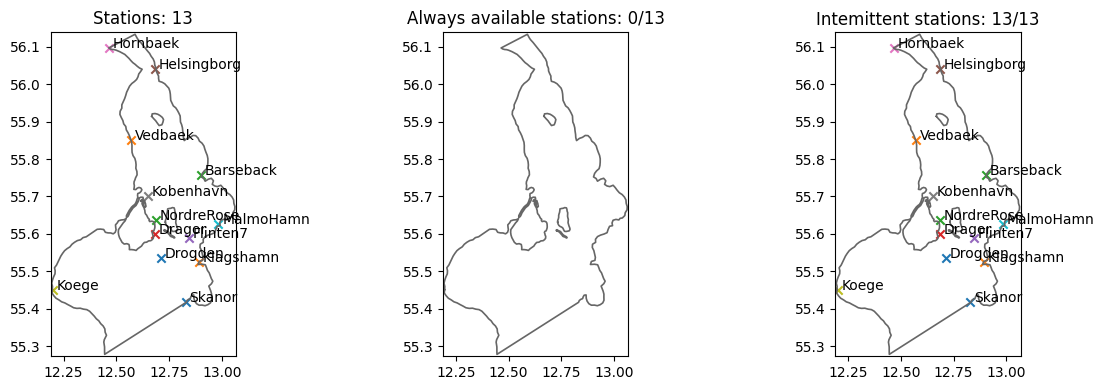

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(wllist)):
    stations.append(wllist[i])
    if ds.time.isin(wllist[i].time).all():
        availables.append(wllist[i])
    else:
        intermittent.append(wllist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intemittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract the values and convert to torch tensors

measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)
print("\nMeasurements shape:", measurements.shape)

# Build a single mask for nodes that are valid in all output fields
surface = ds["Surface elevation"].values
u_velocity = ds["U velocity"].values
v_velocity = ds["V velocity"].values
valid_nodes = np.isfinite(surface).all(axis=0) & np.isfinite(u_velocity).all(axis=0) & np.isfinite(v_velocity).all(axis=0)

# outputs
H = torch.from_numpy(surface[:, valid_nodes].astype(np.float32, copy=False))
U = torch.from_numpy(u_velocity[:, valid_nodes].astype(np.float32, copy=False))
V = torch.from_numpy(v_velocity[:, valid_nodes].astype(np.float32, copy=False))

# inputs
measurements = torch.as_tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("\nH shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del surface, u_velocity, v_velocity, valid_nodes

Extracted measurements for station Drogden from datasets/observations/Drogden_wl.csv
Extracted measurements for station Klagshamn from datasets/observations/Klagshamn_wl.csv
Extracted measurements for station Barseback from datasets/observations/Barseback_wl.csv
Extracted measurements for station Dragor from datasets/observations/Dragor_wl.csv
Extracted measurements for station Flinten7 from datasets/observations/Flinten7_wl.csv
Extracted measurements for station Helsingborg from datasets/observations/Helsingborg_wl.csv
Extracted measurements for station Hornbaek from datasets/observations/Hornbaek_wl.csv
Extracted measurements for station Kobenhavn from datasets/observations/Kobenhavn_wl.csv
Extracted measurements for station Koege from datasets/observations/Koege_wl.csv
Extracted measurements for station MalmoHamn from datasets/observations/MalmoHamn_wl.csv
Extracted measurements for station Skanor from datasets/observations/Skanor_wl.csv
Extracted measurements for station Vedbaek fr